SAMPLE MARKETING DATA
     campaign  exposed  clicked  lead  converted  order_value
0  Campaign C        1        0     0          0          0.0
1  Campaign A        1        1     0          0          0.0
2  Campaign C        1        0     0          0          0.0
3  Campaign C        1        1     1          0          0.0
4  Campaign A        1        0     0          0          0.0
5  Campaign A        1        0     0          0          0.0
6  Campaign C        1        0     0          0          0.0
7  Campaign B        1        1     0          0          0.0
8  Campaign C        1        1     1          0          0.0
9  Campaign C        1        1     0          0          0.0

CAMPAIGN PERFORMANCE SUMMARY
  campaign  exposures  clicks  leads  conversions  revenue  CTR_pct  click_to_lead_pct  lead_to_sale_pct  revenue_per_conversion
Campaign A        520     171     71           13  3721.28    32.88              41.52             18.31                  286.25
Campaign

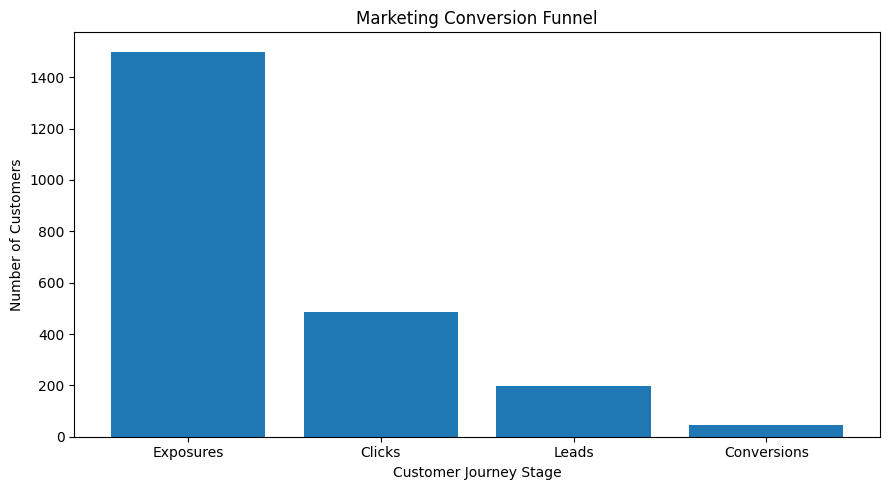

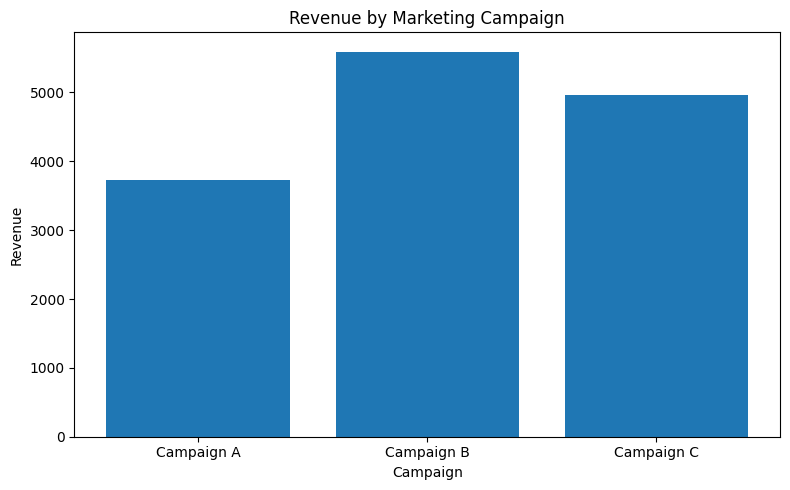

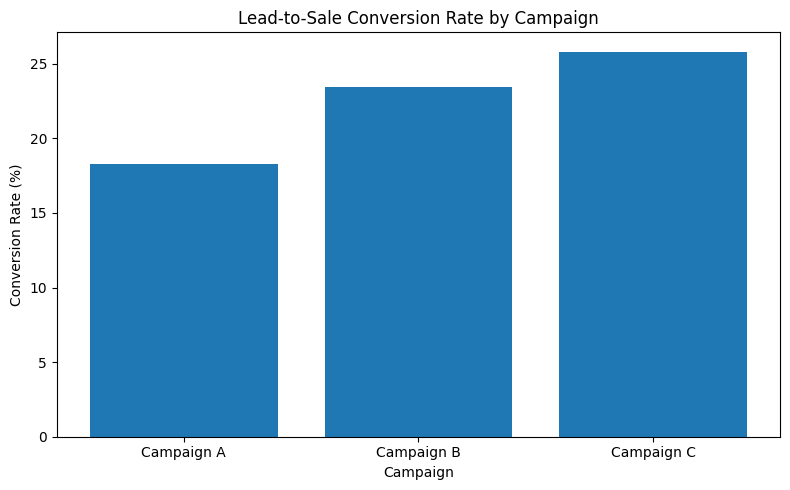


TOP CAMPAIGN BY REVENUE
Campaign: Campaign B
Revenue: 5593.07
Conversions: 15

MARKETING FUNNEL ANALYSIS
Exposure-to-click drop-off: 67.53 %
Click-to-lead drop-off: 59.55 %
Lead-to-sale drop-off: 77.66 %

BUSINESS RECOMMENDATIONS
1. Improve campaign messages if click-through rates are low.
2. Review landing pages and lead forms to improve lead generation.
3. Investigate sales follow-up if lead-to-sale conversion is low.
4. Compare revenue and conversion quality across campaigns.
5. Track customer journeys using reliable campaign-level data.

PROJECT 3 COMPLETED SUCCESSFULLY
Note: This project uses synthetic data for demonstration.


In [2]:

# PROJECT 3: MARKETING-TO-REVENUE ATTRIBUTION

# STEP 1: IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(42)


# STEP 2: GENERATE MARKETING CAMPAIGN DATA

n = 1500

df = pd.DataFrame({
    "campaign": np.random.choice(
        ["Campaign A", "Campaign B", "Campaign C"],
        n
    ),
    "exposed": 1,
    "clicked": np.random.binomial(1, 0.32, n)
})

# Generate leads from clicked users
df["lead"] = (
    df["clicked"] *
    np.random.binomial(1, 0.42, n)
)

# Generate sales conversions from leads
df["converted"] = (
    df["lead"] *
    np.random.binomial(1, 0.22, n)
)

# Generate revenue for converted customers
df["order_value"] = np.where(
    df["converted"] == 1,
    np.random.uniform(50, 600, n),
    0
)

print("SAMPLE MARKETING DATA")
print(df.head(10))


# STEP 3: ANALYZE CAMPAIGN PERFORMANCE

summary = df.groupby("campaign").agg(
    exposures=("exposed", "sum"),
    clicks=("clicked", "sum"),
    leads=("lead", "sum"),
    conversions=("converted", "sum"),
    revenue=("order_value", "sum")
).reset_index()

# Calculate click-through rate
summary["CTR_pct"] = (
    summary["clicks"] / summary["exposures"] * 100
).round(2)

# Calculate click-to-lead rate
summary["click_to_lead_pct"] = (
    summary["leads"] / summary["clicks"].replace(0, np.nan) * 100
).round(2)

# Calculate lead-to-sale conversion rate
summary["lead_to_sale_pct"] = (
    summary["conversions"] /
    summary["leads"].replace(0, np.nan) * 100
).round(2)

# Calculate revenue per conversion
summary["revenue_per_conversion"] = (
    summary["revenue"] /
    summary["conversions"].replace(0, np.nan)
).round(2)

print("\nCAMPAIGN PERFORMANCE SUMMARY")
print(summary.round(2).to_string(index=False))


# STEP 4: VISUALIZE THE MARKETING FUNNEL

funnel = pd.Series({
    "Exposures": df["exposed"].sum(),
    "Clicks": df["clicked"].sum(),
    "Leads": df["lead"].sum(),
    "Conversions": df["converted"].sum()
})

plt.figure(figsize=(9, 5))
plt.bar(funnel.index, funnel.values)

plt.title("Marketing Conversion Funnel")
plt.xlabel("Customer Journey Stage")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()


# STEP 5: COMPARE CAMPAIGN REVENUE

plt.figure(figsize=(8, 5))

plt.bar(
    summary["campaign"],
    summary["revenue"]
)

plt.title("Revenue by Marketing Campaign")
plt.xlabel("Campaign")
plt.ylabel("Revenue")

plt.tight_layout()
plt.show()


# STEP 6: COMPARE CONVERSION RATES

plt.figure(figsize=(8, 5))

plt.bar(
    summary["campaign"],
    summary["lead_to_sale_pct"]
)

plt.title("Lead-to-Sale Conversion Rate by Campaign")
plt.xlabel("Campaign")
plt.ylabel("Conversion Rate (%)")

plt.tight_layout()
plt.show()


# STEP 7: IDENTIFY THE TOP CAMPAIGN BY REVENUE

best_campaign = summary.loc[
    summary["revenue"].idxmax()
]

print("\nTOP CAMPAIGN BY REVENUE")
print("Campaign:", best_campaign["campaign"])
print("Revenue:", round(best_campaign["revenue"], 2))
print("Conversions:", int(best_campaign["conversions"]))


# STEP 8: IDENTIFY WHERE CUSTOMERS DROP OFF

total_exposures = len(df)
total_clicks = df["clicked"].sum()
total_leads = df["lead"].sum()
total_conversions = df["converted"].sum()

print("\nMARKETING FUNNEL ANALYSIS")

print(
    "Exposure-to-click drop-off:",
    round((1 - total_clicks / total_exposures) * 100, 2),
    "%"
)

if total_clicks > 0:
    print(
        "Click-to-lead drop-off:",
        round((1 - total_leads / total_clicks) * 100, 2),
        "%"
    )

if total_leads > 0:
    print(
        "Lead-to-sale drop-off:",
        round((1 - total_conversions / total_leads) * 100, 2),
        "%"
    )


# STEP 9: BUSINESS RECOMMENDATIONS

print("\nBUSINESS RECOMMENDATIONS")

print("1. Improve campaign messages if click-through rates are low.")
print("2. Review landing pages and lead forms to improve lead generation.")
print("3. Investigate sales follow-up if lead-to-sale conversion is low.")
print("4. Compare revenue and conversion quality across campaigns.")
print("5. Track customer journeys using reliable campaign-level data.")

print("\nPROJECT 3 COMPLETED SUCCESSFULLY")
print("Note: This project uses synthetic data for demonstration.")
